# Evaluating Natural Language Explanations of Food Recommendation System XFoodRec Across Several LLMs

# Evaluating Natural Language Explanations of Food Recommendation System XFoodRec Across Several LLMs

Authors: Junxuan Ling, Tianyi Liu, Anqi Zhou

# 0. Document Instructions

## 0.1. Git Version Control

After making modifications, please use Colab's function of "Save in Github to keep changes" (Github authorization required) to commit the changes to the repository (Your own branch if needed).

**NOTE**: When A modifies this notebook, but have not commited to Github, if B opens this notebook, they will see the Github old version.

## 0.2. Handle persistent data storage

Mount Google Drive instead of relying on Colab's temporary run-time storage.

**IMPORTANT:** Although Google Colab allows collaboration of the notebook, data and folders are originally in Junxuan's drive, this could cause issues when refering to the mounted directory path. To allow the code to work for all of us, (who's not junxuan) please create a **short-cut** of Junxuan's shared folder in our own Google Drive, path `MyDrive/`.

In [1]:
# load from drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 0.3 Setup and data loading

Run the notebook from top to bottom. It does not parse the explanations again; it reads what Step 2 saved in 2.1e.

| File | Saved by | Used for |
|---|---|---|
| `explanation_lemmas.parquet` | Step 1 (preprocessing) | The 536 explanations with their persona, recipe and rank |
| `explanation_docs.spacy` | Step 2 (2.1e) | The parsed explanations, with each word's base form and whether it belongs to the recipe title |
| `user_factor_mentions.parquet` | Step 2 (2.1e) | Where each explanation names its persona's own values |

**Shared files:** everything in `processed/` is shared by the whole team. Rerunning the 2.1e cells of Step 2 overwrites these files for everyone. If a rule in Step 2 (2.0 or 2.1) changes, rerun Step 2 up to 2.1e before this notebook, otherwise this notebook reads the old results. The last cell here saves `transparency_levels.parquet` in the same folder.

In [2]:
%pip install -q spacy pyarrow

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from spacy.tokens import DocBin

project_dir = Path("/content/drive/MyDrive/XFoodRec_Project_Data")
data_dir = project_dir / "raw"
processed_dir = project_dir / "processed"
persona_path = data_dir / "personas.json"

In [4]:
# raw persona profiles and explanations
with (data_dir / "personas.json").open("r", encoding="utf-8") as f:
    personas = json.load(f)

with (data_dir / "recommendations.json").open("r", encoding="utf-8") as f:
    recommendations = json.load(f)

# explanation identifiers from task 1
explanation_index = pd.read_parquet(
    processed_dir / "explanation_lemmas.parquet"
)[["recommendation_id", "persona_id", "recipe_id", "rank"]]

# explanation-level transparency from task 3
transparency_df = pd.read_parquet(
    processed_dir / "transparency_levels.parquet"
)

# claim-level verification from task 2
verified_claims_df = pd.read_parquet(
    processed_dir / "verified_claims.parquet"
)

assert explanation_index["recommendation_id"].is_unique
assert transparency_df["recommendation_id"].is_unique

assert set(transparency_df["recommendation_id"]) == set(
    explanation_index["recommendation_id"]
), "transparency and explanation ids differ"

assert verified_claims_df["recommendation_id"].isin(
    explanation_index["recommendation_id"]
).all(), "claims contain unknown explanation ids"

print("Personas:", len(personas))
print("Explanations:", len(explanation_index))
print("Transparency records:", len(transparency_df))
print("Verified claims:", len(verified_claims_df))

Personas: 40
Explanations: 536
Transparency records: 536
Verified claims: 1551


# 4. Bias & Fairness Analysis

## 4.1 Investigate persona characteristics

### a. Dietary goal

In [7]:
personas_df = pd.json_normalize(personas).rename(
    columns={"id": "persona_id"}
)

assert personas_df["persona_id"].is_unique, "duplicate persona ids"

# keep the original goal
personas_df["dietary_goal"] = (
    personas_df["profile.dietary_goal"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

goal_summary = (
    personas_df["dietary_goal"]
    .fillna("missing")
    .value_counts()
    .rename_axis("dietary_goal")
    .to_frame("personas")
)

goal_summary["percent"] = (
    100 * goal_summary["personas"] / len(personas_df)
).round(1)

display(goal_summary)
print("\nPersonas:", len(personas_df))
print("Missing dietary goals:", personas_df["dietary_goal"].isna().sum())

,personas,percent
dietary_goal,,
Medical Management,14,35.0
Maintenance,8,20.0
Weight Loss,7,17.5
Energy Boost,6,15.0
Muscle Gain,5,12.5



Personas: 40
Missing dietary goals: 0


### b. Health status

In [8]:
selected_conditions = personas_df[
    "profile.dietaryProfile.healthConditions.selected"
]

personas_df["health_status"] = selected_conditions.map(
    lambda values: ("yes" if len(values) else "no")
    if isinstance(values, (list, np.ndarray))
    else pd.NA
)

health_summary = (
    personas_df["health_status"]
    .fillna("missing")
    .value_counts()
    .rename_axis("health_status")
    .to_frame("personas")
)

health_summary["percent"] = (
    100 * health_summary["personas"] / len(personas_df)
).round(1)

display(health_summary)
print("Missing health status:", personas_df["health_status"].isna().sum())

,personas,percent
health_status,,
yes,30,75.0
no,10,25.0


Missing health status: 0


In [9]:
# health information rather than selected
health_other = personas_df[
    "profile.dietaryProfile.healthConditions.other"
].astype("string").str.strip()

display(
    personas_df.loc[
        health_other.fillna("").ne(""),
        [
            "persona_id",
            "health_status",
            "profile.dietaryProfile.healthConditions.selected",
            "profile.dietaryProfile.healthConditions.other",
        ],
    ]
)

,persona_id,health_status,profile.dietaryProfile.healthConditions.selected,profile.dietaryProfile.healthConditions.other
3,user_04,yes,[Anemia],Iron-deficiency anemia
5,user_06,yes,[Post-Surgery],Post-bariatric surgery
7,user_08,yes,[Kidney Disease],CKD stage 3
9,user_10,yes,[Autism Spectrum],Sensory processing challenges
12,user_13,yes,[PKU],Phenylketonuria
13,user_14,yes,[Food Allergy],Alpha-gal syndrome
17,user_18,yes,[ARFID],Avoidant/Restrictive Food Intake Disorder
20,user_21,yes,[EoE],Eosinophilic esophagitis
33,user_34,yes,[Pancreatitis],Chronic pancreatitis
37,user_38,yes,[Food Allergy],Oral allergy syndrome


### c. Dietary restriction

In [10]:
selected_restrictions = personas_df[
    "profile.dietaryProfile.dietaryRestrictions.selected"
]

personas_df["dietary_restriction"] = selected_restrictions.map(
    lambda values: ("yes" if len(values) else "no")
    if isinstance(values, (list, np.ndarray))
    else pd.NA
)

restriction_summary = (
    personas_df["dietary_restriction"]
    .fillna("missing")
    .value_counts()
    .rename_axis("dietary_restriction")
    .to_frame("personas")
)

restriction_summary["percent"] = (
    100 * restriction_summary["personas"] / len(personas_df)
).round(1)

display(restriction_summary)
print("Missing dietary restriction:", personas_df["dietary_restriction"].isna().sum())

,personas,percent
dietary_restriction,,
yes,32,80.0
no,8,20.0


Missing dietary restriction: 0


In [11]:
# restrictions rather than selected
restriction_other = personas_df[
    "profile.dietaryProfile.dietaryRestrictions.other"
].astype("string").str.strip()

display(
    personas_df.loc[
        restriction_other.fillna("").ne(""),
        [
            "persona_id",
            "dietary_restriction",
            "profile.dietaryProfile.dietaryRestrictions.selected",
            "profile.dietaryProfile.dietaryRestrictions.other",
        ],
    ]
)

,persona_id,dietary_restriction,profile.dietaryProfile.dietaryRestrictions.selected,profile.dietaryProfile.dietaryRestrictions.other
0,user_01,yes,[Vegan],"High-protein, prefers low-soy options"
1,user_02,yes,[Low Carb],Counts carbs precisely; prefers low-GI foods
2,user_03,yes,[Lactose-Free],Very budget-constrained; batch-cooks
3,user_04,yes,[Vegetarian],"Pregnant; prioritizes iron, folate, choline"
4,user_05,yes,[Gluten-Free],Endurance fueling; needs portable snacks
5,user_06,yes,[High Protein],Small meals; avoids high sugar/fat dumping tri...
6,user_07,yes,[Pescatarian],Avoids shellfish; prefers fatty fish
7,user_08,yes,[Keto],Must monitor potassium/phosphorus; moderate pr...
8,user_09,yes,[Low Acid],Avoids trigger foods on shift; prefers easy prep
9,user_10,no,[],Strong texture aversions; prefers predictable ...


### d. Demographics (age, gender)

In [13]:
personas_df["age"] = pd.to_numeric(
    personas_df["profile.age"], errors="coerce"
)

assert personas_df["age"].dropna().between(0, 120).all(), "check age values"

# use the same age groups as in task 3
personas_df["age_group"] = pd.cut(
    personas_df["age"],
    bins=[0, 18, 40, 60, np.inf],
    labels=["under 18", "18-39", "40-59", "60+"],
    right=False
)

age_summary = (
    personas_df["age_group"]
    .value_counts(sort=False)
    .rename_axis("age_group")
    .to_frame("personas")
)

age_summary["percent"] = (
    100 * age_summary["personas"] / len(personas_df)
).round(1)

display(age_summary)
print("\nMissing age:", personas_df["age"].isna().sum())

,personas,percent
age_group,,
under 18,3,7.5
18-39,21,52.5
40-59,12,30.0
60+,4,10.0



Missing age: 0


In [14]:
# gender categories
personas_df["gender"] = (
    personas_df["profile.gender"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

gender_summary = (
    personas_df["gender"]
    .fillna("missing")
    .value_counts()
    .rename_axis("gender")
    .to_frame("personas")
)

gender_summary["percent"] = (
    100 * gender_summary["personas"] / len(personas_df)
).round(1)

display(gender_summary)

print("\nMissing gender:", personas_df["gender"].isna().sum())

,personas,percent
gender,,
Female,20,50.0
Male,19,47.5
Non-binary,1,2.5



Missing gender: 0


In [16]:
# display personas demographics
display(
    personas_df[
        [
            "persona_id",
            "dietary_goal",
            "health_status",
            "dietary_restriction",
            "age",
            "age_group",
            "gender",
        ]
    ]
)

,persona_id,dietary_goal,health_status,dietary_restriction,age,age_group,gender
0,user_01,Muscle Gain,no,yes,28,18-39,Male
1,user_02,Medical Management,yes,yes,34,18-39,Female
2,user_03,Weight Loss,no,yes,20,18-39,Non-binary
3,user_04,Medical Management,yes,yes,31,18-39,Female
4,user_05,Energy Boost,yes,yes,26,18-39,Male
5,user_06,Medical Management,yes,yes,45,40-59,Female
6,user_07,Maintenance,yes,yes,52,40-59,Male
7,user_08,Medical Management,yes,yes,60,60+,Female
8,user_09,Energy Boost,yes,yes,29,18-39,Female
9,user_10,Maintenance,yes,no,24,18-39,Male


#### e. persona gorup summary

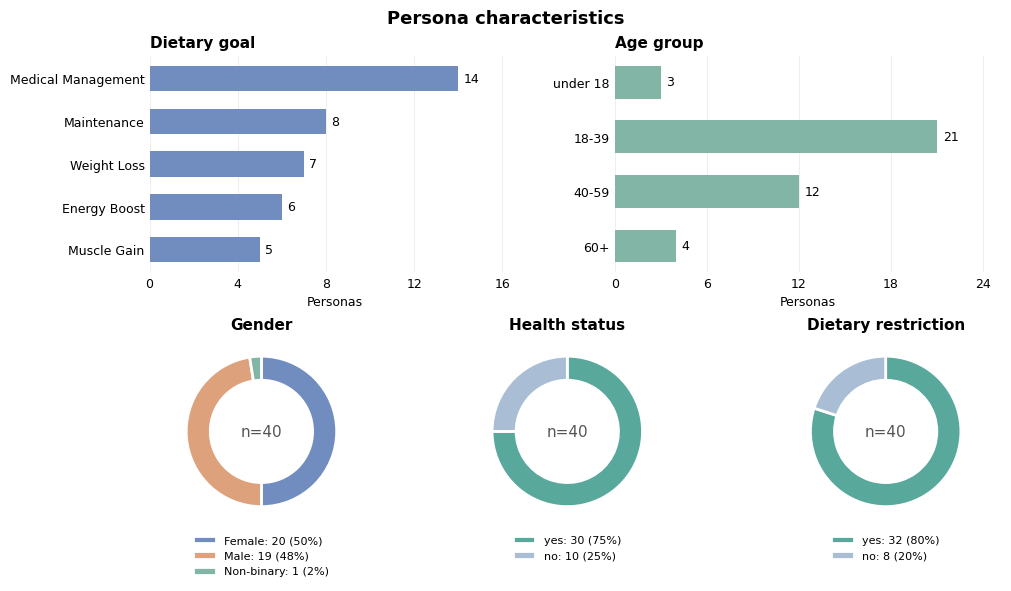

In [21]:
from matplotlib.ticker import MaxNLocator

# compact layout with consistent category colors
colors = {
    "yes": "#59A89C",
    "no": "#A9BED5",
    "missing": "#D9D9D9",
}
palette = ["#718DBF", "#DDA17C", "#83B5A6", "#B69AC5", "#D8C17A"]

fig = plt.figure(figsize=(10, 5.8), layout="constrained")
grid = fig.add_gridspec(2, 6, height_ratios=[1.15, 1])

bar_tables = [
    ("Dietary goal", goal_summary, grid[0, :3]),
    ("Age group", age_summary, grid[0, 3:]),
]

for title, table, position in bar_tables:
    ax = fig.add_subplot(position)
    bars = ax.barh(
        table.index.astype(str),
        table["personas"],
        color="#718DBF" if title == "Dietary goal" else "#83B5A6",
        height=0.6,
    )

    ax.bar_label(bars, padding=4, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, max(1, table["personas"].max()) * 1.2)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Personas", fontsize=9)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color="#EEEEEE")
    ax.tick_params(axis="both", length=0, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

donut_tables = [
    ("Gender", gender_summary, grid[1, :2]),
    ("Health status", health_summary, grid[1, 2:4]),
    ("Dietary restriction", restriction_summary, grid[1, 4:]),
]

for title, table, position in donut_tables:
    ax = fig.add_subplot(position)
    counts = table.loc[table["personas"].gt(0), "personas"]
    labels = counts.index.astype(str)

    slice_colors = [
        colors.get(label.lower(), palette[i % len(palette)])
        for i, label in enumerate(labels)
    ]

    wedges, _ = ax.pie(
        counts,
        colors=slice_colors,
        startangle=90,
        counterclock=False,
        wedgeprops={"width": 0.32, "edgecolor": "white", "linewidth": 2},
    )

    ax.text(
        0, 0, f"n={int(counts.sum())}",
        ha="center", va="center", fontsize=11, color="#555555",
    )
    ax.set_title(title, fontsize=11, fontweight="bold")

    ax.legend(
        wedges,
        [
            f"{label}: {count} ({count / counts.sum():.0%})"
            for label, count in zip(labels, counts)
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, 0),
        frameon=False,
        fontsize=8,
    )

fig.suptitle(
    f"Persona characteristics",
    fontsize=13,
    fontweight="bold",
)

plt.show()

## 4.2 Explanation Quality Metrics

### a. Average explanation length

### b. Transparency score

### c. Hallucination rate

### d. Aggregate metrics per persona

## 4.3 Statistical Testing

### a. Check group sizes and test assumptions

### b. T-tests for binary factors

### c. One-way ANOVA for multi-group factors

### d. Multiple-testing correction (Benjamini–Hochberg FDR)

### e. Summarize group differences and effect sizes

## 4.4 Save Analysis Results